In [1]:
import os, sys, time
from pathlib import Path

PROJECT = Path(r"C:\Users\hp\Documents\teliport_prototype")
os.chdir(PROJECT / "notebooks")              # notebook kahin bhi ho, kaam yahin se hoga
sys.path.insert(0, str(PROJECT / "src"))
%load_ext autoreload
%autoreload 2

import numpy as np, pandas as pd, joblib
import matplotlib.pyplot as plt
from sklearn.metrics import adjusted_rand_score
from cmapss_data import load_all, SUBSETS

DATA_DIR = PROJECT / "data" / "raw" / "CMAPSS"
PROC = PROJECT / "data" / "processed"; PROC.mkdir(parents=True, exist_ok=True)
MODELS = PROJECT / "models"; MODELS.mkdir(exist_ok=True)
FIG_DIR = PROJECT / "reports" / "figures"
data = load_all(DATA_DIR)
print("Project root:", PROJECT)
print("Working dir :", Path.cwd())

Project root: C:\Users\hp\Documents\teliport_prototype
Working dir : C:\Users\hp\Documents\teliport_prototype\notebooks


In [2]:
%%writefile ../src/features.py
"""Data engineering for C-MAPSS: cleaning, regime normalization, causal rolling features.

Every feature at cycle t uses only data from cycles <= t, so the exact same code
works for batch training and for live streaming data.
"""
from __future__ import annotations

import numpy as np
import pandas as pd
from sklearn.cluster import KMeans
from sklearn.preprocessing import StandardScaler

from cmapss_data import OP_COLS, SUBSET_INFO

SELECTED_SENSORS = ["s2", "s3", "s4", "s7", "s8", "s9", "s11",
                    "s12", "s13", "s14", "s15", "s17", "s20", "s21"]
DEFAULT_RUL_CAP = 125


class CMAPSSPreprocessor:
    """sklearn-style fit/transform. Fit on TRAIN only, then reuse for test / new data."""

    def __init__(self, n_regimes=1, sensors=SELECTED_SENSORS, mean_windows=(5, 15, 30),
                 std_window=10, slope_windows=(10, 30), ewm_span=10,
                 baseline_cycles=10, clip_z=6.0, spike_z=4.0, random_state=42):
        self.n_regimes = n_regimes
        self.sensors = list(sensors)
        self.mean_windows = tuple(mean_windows)
        self.std_window = std_window
        self.slope_windows = tuple(slope_windows)
        self.ewm_span = ewm_span
        self.baseline_cycles = baseline_cycles
        self.clip_z = clip_z
        self.spike_z = spike_z
        self.random_state = random_state

    @classmethod
    def for_subset(cls, fd, **kw):
        return cls(n_regimes=SUBSET_INFO[fd]["conditions"], **kw)

    # ---------- cleaning ----------
    def _clean(self, df):
        cols = OP_COLS + self.sensors
        out = df.copy()
        out[cols] = out[cols].apply(pd.to_numeric, errors="coerce")       # bad strings -> NaN
        out = (out.drop_duplicates(subset=["unit", "cycle"], keep="last")  # duplicate readings
                  .sort_values(["unit", "cycle"]).reset_index(drop=True))  # out-of-order data
        out[cols] = out.groupby("unit")[cols].ffill()                      # carry last good reading
        out[cols] = out.groupby("unit")[cols].bfill()                      # gap at the very start
        out[cols] = out[cols].fillna(self.fill_values_)                    # whole column missing
        return out

    # ---------- fit ----------
    def fit(self, df):
        self.fill_values_ = df[OP_COLS + self.sensors].median(numeric_only=True)
        clean = self._clean(df)
        ops = clean[OP_COLS].to_numpy(dtype=float)
        self.op_scaler_ = StandardScaler().fit(ops)
        self.kmeans_ = KMeans(n_clusters=self.n_regimes, n_init=10,
                              random_state=self.random_state).fit(self.op_scaler_.transform(ops))
        reg = self.kmeans_.labels_
        self.mu_ = clean[self.sensors].groupby(reg).mean()
        sd = clean[self.sensors].groupby(reg).std()
        self.sd_ = sd.where(sd > 1e-8, 1.0).fillna(1.0)
        self.feature_names_ = None
        return self

    def regimes(self, df):
        ops = df[OP_COLS].to_numpy(dtype=float)
        return self.kmeans_.predict(self.op_scaler_.transform(ops))

    # ---------- transform ----------
    def transform(self, df):
        out = self._clean(df)
        S = self.sensors
        reg = self.regimes(out)
        out["regime"] = reg
        # regime-wise z-score, then hard clip of extreme values
        z = (out[S].to_numpy() - self.mu_.loc[reg].to_numpy()) / self.sd_.loc[reg].to_numpy()
        z = np.clip(z, -self.clip_z, self.clip_z)
        Z = pd.DataFrame(z, columns=S, index=out.index)
        unit = out["unit"]
        # spike filter (causal Hampel-style): isolated outliers -> rolling median of last 5 cycles
        med = Z.groupby(unit).rolling(5, min_periods=1).median().reset_index(level=0, drop=True)
        Z = Z.mask((Z - med).abs() > self.spike_z, med)
        g = Z.groupby(unit)
        feats = {}

        for s in S:                                        # current (cleaned) value
            feats[f"{s}_z"] = Z[s]
        ewm = g.transform(lambda x: x.ewm(span=self.ewm_span, adjust=False).mean())
        for s in S:                                        # smoothed level (noise filter)
            feats[f"{s}_ewm"] = ewm[s]
        for w in self.mean_windows:                        # rolling averages
            m = g.rolling(w, min_periods=1).mean().reset_index(level=0, drop=True)
            for s in S:
                feats[f"{s}_mean{w}"] = m[s]
        sd = g.rolling(self.std_window, min_periods=2).std().reset_index(level=0, drop=True).fillna(0.0)
        for s in S:                                        # recent volatility
            feats[f"{s}_std{self.std_window}"] = sd[s]

        t = out["cycle"].astype(float)                     # rolling linear-regression slope = trend
        T = pd.concat([Z, Z.mul(t, axis=0).add_suffix("_tx")], axis=1)
        T["t"], T["tt"] = t, t * t
        gT = T.groupby(unit)
        for w in self.slope_windows:
            r = gT.rolling(w, min_periods=1).mean().reset_index(level=0, drop=True)
            var_t = (r["tt"] - r["t"] ** 2).to_numpy()
            for s in S:
                cov = (r[f"{s}_tx"] - r["t"] * r[s]).to_numpy()
                feats[f"{s}_slope{w}"] = np.where(var_t > 1e-9, cov / np.where(var_t > 1e-9, var_t, 1.0), 0.0)

        # drift from the engine's own early-life baseline (handles different initial wear)
        pos = out.groupby("unit").cumcount()
        early = Z.where(np.repeat((pos.to_numpy() < self.baseline_cycles)[:, None], len(S), axis=1))
        base = early.groupby(unit).expanding().mean().reset_index(level=0, drop=True).groupby(unit).ffill()
        for s in S:
            feats[f"{s}_dbase"] = ewm[s] - base[s]

        F = pd.DataFrame(feats, index=out.index)
        F.insert(0, "cycle", out["cycle"].astype(float))
        self.feature_names_ = list(F.columns)
        meta = [c for c in ["unit", "subset", "regime", "RUL"] if c in out.columns]
        return pd.concat([out[meta], F], axis=1)

    def fit_transform(self, df):
        return self.fit(df).transform(df)


def add_targets(df, cap=DEFAULT_RUL_CAP):
    out = df.copy()
    out["RUL_capped"] = out["RUL"].clip(upper=cap)
    return out


def last_cycle(df):
    """One row per engine: the most recent cycle (what we predict on for test engines)."""
    return df.groupby("unit", sort=True).tail(1).reset_index(drop=True)

Writing ../src/features.py


In [3]:
from features import CMAPSSPreprocessor, add_targets, last_cycle

def rounded_regime(df):
    r = pd.DataFrame({"a": df["op_setting_1"].round(0) + 0.0,
                      "b": df["op_setting_2"].round(2) + 0.0,
                      "c": df["op_setting_3"].round(0) + 0.0})
    return r.groupby(["a", "b", "c"]).ngroup()

rows = []
for fd in SUBSETS:
    train, test, rul = data[fd]
    t0 = time.time()
    prep = CMAPSSPreprocessor.for_subset(fd)
    tr = add_targets(prep.fit_transform(train))            # fit on TRAIN only
    te = prep.transform(test)                              # reuse fitted stats on TEST
    te_last = last_cycle(te).merge(rul[["unit", "RUL"]], on="unit")
    truth = rounded_regime(train.sort_values(["unit", "cycle"]).reset_index(drop=True))

    tr.to_pickle(PROC / f"train_{fd}.pkl")
    te.to_pickle(PROC / f"test_{fd}.pkl")
    te_last.to_pickle(PROC / f"test_last_{fd}.pkl")
    joblib.dump(prep, MODELS / f"preprocessor_{fd}.joblib")

    F = prep.feature_names_
    rows.append({"subset": fd, "train_shape": tr.shape, "test_engines": len(te_last),
                 "n_features": len(F),
                 "NaNs": int(tr[F].isna().sum().sum() + te[F].isna().sum().sum()),
                 "regime_ARI": round(adjusted_rand_score(truth, tr["regime"]), 4),
                 "secs": round(time.time() - t0, 1)})

pd.DataFrame(rows).set_index("subset")

,train_shape,test_engines,n_features,NaNs,regime_ARI,secs
subset,,,,,,
FD001,"(20631, 132)",100,127,0,1.0,2.9
FD002,"(53759, 132)",259,127,0,1.0,6.3
FD003,"(24720, 132)",100,127,0,1.0,2.4
FD004,"(61249, 132)",248,127,0,1.0,6.1


In [4]:
train, test, rul = data["FD001"]
prep = joblib.load(MODELS / "preprocessor_FD001.joblib")
F = prep.feature_names_
clean_last = last_cycle(prep.transform(test))

rng = np.random.default_rng(0)
dirty = test.copy()
vals = dirty[prep.sensors].to_numpy(dtype=float)
vals[rng.random(vals.shape) < 0.03] = np.nan                      # 3% missing readings
dirty[prep.sensors] = vals
spike = rng.random(len(dirty)) < 0.005
dirty.loc[spike, "s11"] = dirty.loc[spike, "s11"] + 50            # sensor glitches
dirty = pd.concat([dirty, dirty.sample(200, random_state=0)])     # duplicate rows
dirty = dirty.sample(frac=1, random_state=1)                      # shuffled order

dirty_last = last_cycle(prep.transform(dirty))
Fz = [f for f in F if f != "cycle"]
per_feat = [np.corrcoef(clean_last[f], dirty_last[f])[0, 1] for f in Fz]
print("Engines out             :", len(dirty_last))
print("NaNs after cleaning     :", int(dirty_last[F].isna().sum().sum()))
print("Median feature corr     :", round(float(np.nanmedian(per_feat)), 4))
print("Worst feature corr      :", round(float(np.nanmin(per_feat)), 4))
print("Mean |difference| (z)   :", round(float((clean_last[Fz] - dirty_last[Fz]).abs().mean().mean()), 4))

Engines out             : 100
NaNs after cleaning     : 0
Median feature corr     : 0.9979
Worst feature corr      : 0.9266
Mean |difference| (z)   : 0.0119


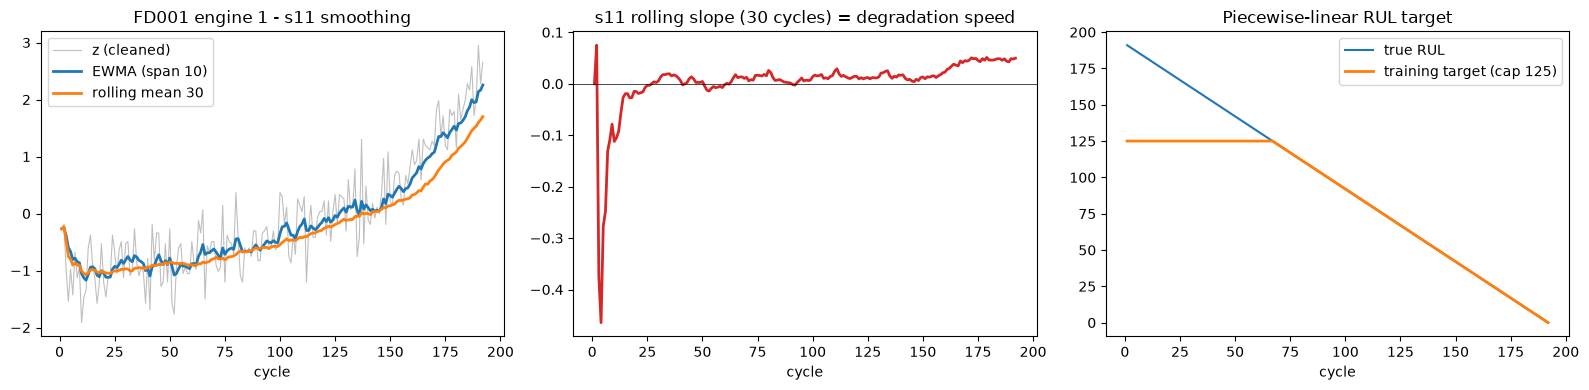

In [5]:
tr = pd.read_pickle(PROC / "train_FD001.pkl")
e = tr[tr["unit"] == 1]
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
axes[0].plot(e["cycle"], e["s11_z"], color="grey", alpha=0.5, lw=0.8, label="z (cleaned)")
axes[0].plot(e["cycle"], e["s11_ewm"], lw=2, label="EWMA (span 10)")
axes[0].plot(e["cycle"], e["s11_mean30"], lw=2, label="rolling mean 30")
axes[0].set_title("FD001 engine 1 - s11 smoothing"); axes[0].legend()
axes[1].plot(e["cycle"], e["s11_slope30"], lw=2, color="tab:red")
axes[1].axhline(0, c="k", lw=0.5); axes[1].set_title("s11 rolling slope (30 cycles) = degradation speed")
axes[2].plot(e["cycle"], e["RUL"], label="true RUL")
axes[2].plot(e["cycle"], e["RUL_capped"], lw=2, label="training target (cap 125)")
axes[2].set_title("Piecewise-linear RUL target"); axes[2].legend()
for ax in axes: ax.set_xlabel("cycle")
fig.tight_layout(); fig.savefig(FIG_DIR / "05_feature_engineering.png", bbox_inches="tight")
plt.show()